# GPU vs CPU EDA: RAPIDS cuDF vs pandas
**DATA 230 Group 6 · Keerat Khandpur**

The report rubric asks for GPU-accelerated EDA **with an explicit comparison to CPU-based EDA** (performance, scalability, insight differences). This notebook runs the **same EDA steps behind our slides** twice, once with pandas (CPU) and once with RAPIDS cuDF (GPU), and compares:
1. **Speed** at our real data size (95,787 games).
2. **Scalability**: the same steps on the data copied 5× and 10× (about 1 million rows), to see where the GPU starts to pay off.
3. **Results**: whether both give the same numbers (they should: same data, same math).

**Setup in Colab:** Runtime → Change runtime type → **T4 GPU**. cuDF comes preinstalled on Colab GPU runtimes.
**Data:** `steam_clean.csv` and `steam_genres_long.csv` from `notebooks/01_cleaning.ipynb` (v2). Put them in Google Drive and set `DATA_DIR` below, or upload them to the Colab Files panel.

In [7]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.environ.get("STEAM_DATA_DIR", "/content/drive/MyDrive/DATA230/clean_output")   # <- change if needed
if not os.path.exists(DATA_DIR) and os.path.exists("/content"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive not mounted:", e)
if not os.path.exists(DATA_DIR):
    DATA_DIR = "."   # files uploaded to the Colab Files panel
CLEAN, GENRES = f"{DATA_DIR}/steam_clean.csv", f"{DATA_DIR}/steam_genres_long.csv"
FIG_DIR = "figures_gpu"; os.makedirs(FIG_DIR, exist_ok=True)

try:
    import cudf
    GPU = True
    print("cuDF", cudf.__version__)
    try:
        import subprocess
        print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True).stdout.strip())
    except Exception:
        pass
except Exception as e:
    GPU = False
    print("cuDF not available, so only the CPU side will run. In Colab: Runtime → Change runtime type → T4 GPU.\n", e)
print("pandas", pd.__version__)

# Only the columns the EDA uses (keeps memory low when we copy the data 10x)
COLS = ["AppID", "publisher", "Price", "price_group", "price_group_order", "publisher_experience",
        "release_year", "success_50k", "total_reviews"]

Mounted at /content/drive
cuDF 26.06.00
Tesla T4, 15360 MiB
pandas 2.2.3


## The EDA steps being timed
Each step is one analysis from our EDA slides. The same function runs on both libraries because cuDF copies the pandas API.

| Step | Analysis | Slide it feeds |
|---|---|---|
| read | Load the clean CSV | all |
| price | Hit rate by price group | Q3 price |
| cohort | Hit rate by release year | Q2 release periods |
| genre | Join genres to games, hit rate per core genre | Q4 genres |
| heatmap | Hit rate by genre × price group | Q6 heatmap |
| publisher | Hit rate by publisher experience | Q5 publishers |
| top_publishers | Per-publisher games and hit rate, keep 20+ games, sort | dashboard detail |

In [8]:
def step_price(lib, g, games):        return games.groupby("price_group")["success_50k"].mean()
def step_cohort(lib, g, games):       return games.groupby("release_year")["success_50k"].mean()
def step_genre(lib, g, games):
    core = g[g["is_core_genre"] == True]
    return core.merge(games[["AppID", "success_50k"]], on="AppID").groupby("genre")["success_50k"].mean()
def step_heatmap(lib, g, games):
    core = g[g["is_core_genre"] == True]
    m = core.merge(games[["AppID", "price_group", "success_50k"]], on="AppID")
    return m.groupby(["genre", "price_group"])["success_50k"].mean()
def step_publisher(lib, g, games):    return games.groupby("publisher_experience")["success_50k"].mean()
def step_top_publishers(lib, g, games):
    t = games.groupby("publisher").agg({"AppID": "count", "success_50k": "mean"})
    return t[t["AppID"] >= 20].sort_values("success_50k", ascending=False)["success_50k"]

STEPS = {"price": step_price, "cohort": step_cohort, "genre": step_genre, "heatmap": step_heatmap,
         "publisher": step_publisher, "top_publishers": step_top_publishers}


def to_pandas(x):
    return x.to_pandas() if hasattr(x, "to_pandas") else x


def timed(fn, repeats=3):
    """Median wall time over repeats. Each run ends with .to_pandas(), so the GPU work is finished
    and the copy back to the CPU is counted: a fair, end-to-end comparison."""
    times, out = [], None
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = to_pandas(fn())
        times.append(time.perf_counter() - t0)
    return float(np.median(times)), out

## 1. Speed at our real size (95,787 games)

In [9]:
rows = []
t_cpu, games_cpu = timed(lambda: pd.read_csv(CLEAN, usecols=COLS), repeats=3)
genres_cpu = pd.read_csv(GENRES)
rows.append({"step": "read", "scale": 1, "cpu_s": t_cpu})
if GPU:
    t_gpu, _ = timed(lambda: cudf.read_csv(CLEAN, usecols=COLS), repeats=3)
    rows[-1]["gpu_s"] = t_gpu
    games_gpu, genres_gpu = cudf.from_pandas(games_cpu), cudf.from_pandas(genres_cpu)

results = {}
for name, fn in STEPS.items():
    t_cpu, out_cpu = timed(lambda: fn(pd, genres_cpu, games_cpu))
    row = {"step": name, "scale": 1, "cpu_s": t_cpu}
    if GPU:
        fn(cudf, genres_gpu, games_gpu)            # warm-up: first GPU call compiles kernels
        t_gpu, out_gpu = timed(lambda: fn(cudf, genres_gpu, games_gpu))
        row["gpu_s"] = t_gpu
        results[name] = (out_cpu, out_gpu)
    rows.append(row)

speed = pd.DataFrame(rows)
if GPU:
    speed["speedup"] = speed["cpu_s"] / speed["gpu_s"]
speed.round(4)

,step,scale,cpu_s,gpu_s,speedup
0,read,1,0.8334,0.1379,6.0446
1,price,1,0.0067,0.0021,3.2159
2,cohort,1,0.0022,0.0018,1.2382
3,genre,1,0.0749,0.0119,6.3015
4,heatmap,1,0.1111,0.0227,4.8900
5,publisher,1,0.0074,0.0022,3.3370
6,top_publishers,1,0.0617,0.0059,10.4465


## 2. Do both give the same answers?
Same data and the same math should give the same numbers. Any difference here would be an "insight difference" to report.

In [10]:
if GPU:
    checks = []
    for name, (a, b) in results.items():
        a, b = a.sort_index(), b.sort_index()
        same_keys = list(a.index) == list(b.index)
        max_diff = (float(np.max(np.abs(a.values - b.values))) if len(a) else 0.0) if same_keys else np.nan
        checks.append({"step": name, "same groups": same_keys, "largest difference": max_diff})
    display(pd.DataFrame(checks))
else:
    print("Run on a GPU runtime to compare results.")

,step,same groups,largest difference
0,price,True,0.0
1,cohort,True,0.0
2,genre,True,0.0
3,heatmap,True,0.0
4,publisher,True,0.0
5,top_publishers,True,0.0


## 3. Scalability: copy the data 5× and 10×
Our 95,787 rows are small for a GPU, where the fixed cost of starting work and copying results back can outweigh the speed-up. Copying the data (with new AppIDs so joins still match one-to-one) shows how each library scales towards a million rows.

In [11]:
def scaled(games, genres, k):
    gs, gg = [], []
    step = int(games["AppID"].max()) + 1
    for i in range(k):
        gs.append(games.assign(AppID=games["AppID"] + i * step))
        gg.append(genres.assign(AppID=genres["AppID"] + i * step))
    return pd.concat(gs, ignore_index=True), pd.concat(gg, ignore_index=True)

for k in (5, 10):
    g_cpu, ge_cpu = scaled(games_cpu, genres_cpu, k)
    if GPU:
        g_gpu, ge_gpu = cudf.from_pandas(g_cpu), cudf.from_pandas(ge_cpu)
    for name, fn in STEPS.items():
        t_cpu, _ = timed(lambda: fn(pd, ge_cpu, g_cpu))
        row = {"step": name, "scale": k, "cpu_s": t_cpu}
        if GPU:
            fn(cudf, ge_gpu, g_gpu)
            row["gpu_s"], _ = timed(lambda: fn(cudf, ge_gpu, g_gpu))
        rows.append(row)
    print(f"{k}x done: {len(g_cpu):,} games, {len(ge_cpu):,} genre rows")

allt = pd.DataFrame(rows)
if GPU:
    allt["speedup"] = allt["cpu_s"] / allt["gpu_s"]
allt.to_csv(f"{FIG_DIR}/gpu_vs_cpu_timings.csv", index=False)
allt.round(4)

5x done: 478,935 games, 1,360,840 genre rows
10x done: 957,870 games, 2,721,680 genre rows


,step,scale,cpu_s,gpu_s,speedup
0,read,1,0.8334,0.1379,6.0446
1,price,1,0.0067,0.0021,3.2159
2,cohort,1,0.0022,0.0018,1.2382
3,genre,1,0.0749,0.0119,6.3015
4,heatmap,1,0.1111,0.0227,4.8900
5,publisher,1,0.0074,0.0022,3.3370
6,top_publishers,1,0.0617,0.0059,10.4465
7,price,5,0.0293,0.0032,9.0755
8,cohort,5,0.0083,0.0030,2.7665
9,genre,5,0.3010,0.0290,10.3970


## 4. Charts for the report

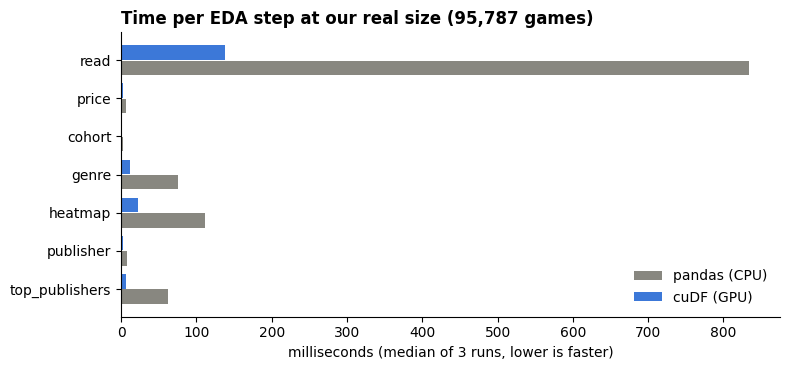

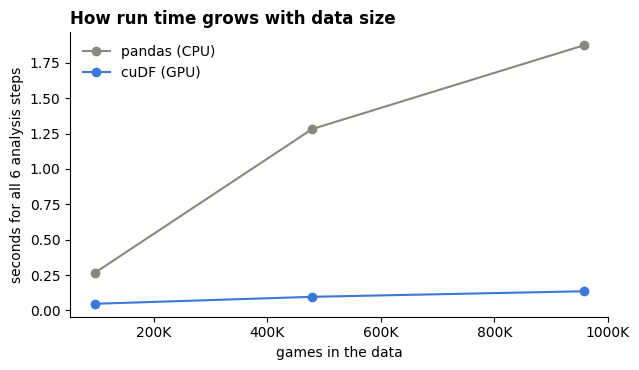

In [12]:
GREY, BLUE = "#888780", "#3C78D8"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Chart 1: time per step at real size
s1 = allt[(allt.scale == 1)].set_index("step")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(s1))
ax.barh(y + 0.2, s1["cpu_s"] * 1000, height=0.38, color=GREY, label="pandas (CPU)")
if GPU:
    ax.barh(y - 0.2, s1["gpu_s"] * 1000, height=0.38, color=BLUE, label="cuDF (GPU)")
ax.set_yticks(y, s1.index); ax.invert_yaxis()
ax.set_xlabel("milliseconds (median of 3 runs, lower is faster)")
ax.set_title(f"Time per EDA step at our real size ({len(games_cpu):,} games)", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gpu_vs_cpu_steps.png", dpi=200); plt.show()

# Chart 2: total time as data grows
tot = allt[allt.step != "read"].groupby("scale")[["cpu_s"] + (["gpu_s"] if GPU else [])].sum()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
n_rows = [int(k * len(games_cpu)) for k in tot.index]
ax.plot(n_rows, tot["cpu_s"], "o-", color=GREY, label="pandas (CPU)")
if GPU:
    ax.plot(n_rows, tot["gpu_s"], "o-", color=BLUE, label="cuDF (GPU)")
ax.set_xlabel("games in the data"); ax.set_ylabel("seconds for all 6 analysis steps")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v/1000:.0f}K"))
ax.set_title("How run time grows with data size", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gpu_vs_cpu_scaling.png", dpi=200); plt.show()

## 5. Summary for the report
Run this and paste the printed lines into the report's GPU vs CPU subsection.

In [13]:
if GPU:
    one = allt[(allt.scale == 1) & (allt.step != "read")]
    ten = allt[(allt.scale == 10)]
    print(f"Real size ({len(games_cpu):,} games): all 6 steps took {one.cpu_s.sum():.3f} s on CPU vs {one.gpu_s.sum():.3f} s on GPU "
          f"({one.cpu_s.sum() / one.gpu_s.sum():.1f}x).")
    print(f"10x size ({10 * len(games_cpu):,} games): {ten.cpu_s.sum():.3f} s on CPU vs {ten.gpu_s.sum():.3f} s on GPU "
          f"({ten.cpu_s.sum() / ten.gpu_s.sum():.1f}x).")
    print("Fastest GPU gain at 10x:", ten.sort_values("speedup").iloc[-1][["step", "speedup"]].to_dict())
    print("Results identical on both: see the check table in section 2.")
else:
    print("CPU-only run: re-run on a T4 GPU runtime for the comparison.")

Real size (95,787 games): all 6 steps took 0.264 s on CPU vs 0.047 s on GPU (5.7x).
10x size (957,870 games): 1.874 s on CPU vs 0.135 s on GPU (13.9x).
Fastest GPU gain at 10x: {'step': 'publisher', 'speedup': 34.74515612510793}
Results identical on both: see the check table in section 2.
